# 02 · Inference

We answer posterior queries with every inference engine NBN has and compare
the answers with the exact truth.

- **NBN API:** `query`, `query_batch`, `map_query`; the engines
  `TensorVariableElimination` (exact), `LikelihoodWeightingEngine`,
  `HybridRouter` (the default, picks one of the two), and the amortized engines
  `AmortizedISEngine` / `AmortizedVIEngine` from `nbn.inference.amortized_is` /
  `nbn.inference.amortized_vi`.
- **Runtime:** under 10 s on a laptop CPU.
- **Install:** `pip install "nbn[examples]"`, then `jupyter lab examples/`.
- **Device:** CUDA or Apple MPS when available, else the CPU (set `NBN_EXAMPLES_DEVICE=cpu` to force the CPU).

Two ground-truth networks:

1. A discrete one, small enough to enumerate all 32 joint states:
   `Cloudy -> Sprinkler`, `Cloudy -> Rain`, `(Sprinkler, Rain) -> WetGrass`,
   `WetGrass -> Slippery`.
2. A hybrid one: `Rain -> Sprinkler`, `(Rain, Sprinkler) -> WetGrass`, and a
   continuous `Soil | WetGrass` that is `N(-1, 0.5^2)` when dry and the bimodal
   `0.5 N(1.5, 0.3^2) + 0.5 N(3, 0.3^2)` when wet.

In [1]:
import itertools
import math
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

from nbn import (
    CategoricalTableMechanism,
    HybridRouter,
    LikelihoodWeightingEngine,
    MDNMechanism,
    NeuralBayesianNetwork,
    TensorVariableElimination,
    seed_all,
)
from nbn.inference.amortized_is import AmortizedISEngine
from nbn.inference.amortized_vi import AmortizedVIEngine
from nbn.utils.device import resolve_device

# "auto" picks CUDA, then Apple MPS, then the CPU.  The stored outputs were made
# with NBN_EXAMPLES_DEVICE=cpu; on an accelerator the last digits can differ.
device = resolve_device(os.environ.get("NBN_EXAMPLES_DEVICE", "auto"))
print("device:", device)

BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
GREY, INK = "#a3a29c", "#0b0b0b"
ENGINE_COLORS = {"variable elimination": BLUE, "likelihood weighting": ORANGE,
                 "amortized IS": AQUA, "amortized VI": MAGENTA}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
                     "font.size": 9})


def to_numpy(t: torch.Tensor):
    """Move to the CPU first, then convert: tensors on MPS / CUDA cannot go to numpy directly."""
    return t.detach().cpu().numpy()


def tv(p: torch.Tensor, q: torch.Tensor) -> torch.Tensor:
    """Total-variation distance between probability vectors (last axis)."""
    return 0.5 * (p.cpu() - q.cpu()).abs().sum(-1)

device: cpu


## The discrete network, with its exact tables

To test inference on its own (without learning error), the model must hold the
true tables.  We get them with a public trick: fit the tables on the 32 joint
states, each weighted by its true probability (`weights=`, see notebook 01).
The weighted counts are then exactly the true conditional tables.

`exact(target, evidence)` sums the 32-state joint, so it is the ground truth.

In [2]:
NAMES = ["Cloudy", "Sprinkler", "Rain", "WetGrass", "Slippery"]
EDGES = [("Cloudy", "Sprinkler"), ("Cloudy", "Rain"), ("Sprinkler", "WetGrass"),
         ("Rain", "WetGrass"), ("WetGrass", "Slippery")]
P_CLOUDY = torch.tensor([0.5, 0.5])
P_SPRINKLER = torch.tensor([[0.5, 0.5], [0.9, 0.1]])               # [cloudy, sprinkler]
P_RAIN = torch.tensor([[0.8, 0.2], [0.2, 0.8]])                    # [cloudy, rain]
P_WET = torch.tensor([[[0.99, 0.01], [0.10, 0.90]],                # [sprinkler, rain, wet]
                      [[0.10, 0.90], [0.01, 0.99]]])
P_SLIPPERY = torch.tensor([[0.95, 0.05], [0.30, 0.70]])            # [wet, slippery]

STATES = torch.tensor(list(itertools.product((0, 1), repeat=5)))   # [32, 5]
c, s, r, w, sl = STATES.T
JOINT = P_CLOUDY[c] * P_SPRINKLER[c, s] * P_RAIN[c, r] * P_WET[s, r, w] * P_SLIPPERY[w, sl]


def exact(targets, evidence: dict) -> torch.Tensor:
    """Exact posterior of one or more targets, by summing the 32-state joint."""
    mask = torch.ones(32, dtype=torch.bool)
    for k, v in evidence.items():
        mask &= STATES[:, NAMES.index(k)] == int(v)
    p = torch.zeros((2,) * len(targets))
    for values in itertools.product((0, 1), repeat=len(targets)):
        sel = mask.clone()
        for t, v in zip(targets, values):
            sel &= STATES[:, NAMES.index(t)] == v
        p[values] = JOINT[sel].sum()
    return p / p.sum()


disc = NeuralBayesianNetwork(EDGES, dict.fromkeys(NAMES, ("discrete", 2)), device=device)
for n in NAMES:
    disc.set_mechanism(n, CategoricalTableMechanism())
disc.fit({n: STATES[:, i] for i, n in enumerate(NAMES)}, weights=JOINT)
print(disc)

NeuralBayesianNetwork(nodes=5, edges=5, fitted_mechanisms=5, device=cpu)


## 1. Exact inference: `TensorVariableElimination`

Variable elimination (VE) sums out the other variables with tensor
contractions.  `query` answers one query; `query_batch` answers one query per
evidence row in a single call.  Here: `P(Cloudy | WetGrass, Slippery)` for the
four evidence patterns.

In [3]:
ve = TensorVariableElimination()
EVIDENCE = {"Sprinkler": torch.tensor([0, 0, 1, 1]), "Slippery": torch.tensor([0, 1, 0, 1])}
truth = {t: torch.stack([exact([t], {"Sprinkler": a, "Slippery": b})
                         for a, b in zip(EVIDENCE["Sprinkler"], EVIDENCE["Slippery"])])
         for t in ("Cloudy", "Rain", "WetGrass")}
p_ve = disc.query_batch(["Cloudy"], EVIDENCE, engine=ve)
print("P(Cloudy = 1 | Sprinkler, Slippery)")
for i in range(4):
    print(f"  Sprinkler={int(EVIDENCE['Sprinkler'][i])}, Slippery={int(EVIDENCE['Slippery'][i])}:"
          f"  VE {float(p_ve[i, 1]):.6f}   exact {float(truth['Cloudy'][i, 1]):.6f}")
ve_err = max(float(tv(disc.query_batch([t], EVIDENCE, engine=ve), truth[t]).max()) for t in truth)
print(f"largest TV distance to the exact answer over 12 queries: {ve_err:.1e}")

P(Cloudy = 1 | Sprinkler, Slippery)
  Sprinkler=0, Slippery=0:  VE 0.511063   exact 0.511063
  Sprinkler=0, Slippery=1:  VE 0.844436   exact 0.844436
  Sprinkler=1, Slippery=0:  VE 0.152636   exact 0.152636
  Sprinkler=1, Slippery=1:  VE 0.174137   exact 0.174137
largest TV distance to the exact answer over 12 queries: 6.7e-08


## 2. Sampling: `LikelihoodWeightingEngine`

Likelihood weighting (LW) draws `n_samples` particles from the network with
the evidence clamped, and weights each particle by the likelihood of the
evidence.  It works with any mechanism, discrete or continuous, but the answer
has Monte-Carlo error.  We run the same 12 queries (3 targets x 4 evidence
patterns) with 10 independent repeats per particle count, and measure the TV
distance to the exact answer.

In [4]:
PARTICLES = [64, 256, 1024, 4096, 16384]
REPEATS = 10


def mean_tv(engine, n_samples: int) -> float:
    errs = [tv(disc.query_batch([t], EVIDENCE, engine=engine, n_samples=n_samples), truth[t])
            for t in truth]
    return float(torch.cat(errs).mean())


seed_all(0)
lw = LikelihoodWeightingEngine()
lw_curve = np.array([[mean_tv(lw, n) for _ in range(REPEATS)] for n in PARTICLES])
for n, errs in zip(PARTICLES, lw_curve):
    print(f"LW, {n:6d} particles: mean TV {errs.mean():.4f}  (min {errs.min():.4f}, max {errs.max():.4f})")

LW,     64 particles: mean TV 0.0327  (min 0.0210, max 0.0408)
LW,    256 particles: mean TV 0.0203  (min 0.0138, max 0.0246)
LW,   1024 particles: mean TV 0.0100  (min 0.0066, max 0.0134)
LW,   4096 particles: mean TV 0.0044  (min 0.0024, max 0.0068)
LW,  16384 particles: mean TV 0.0023  (min 0.0017, max 0.0035)


## 3. Amortized engines

The amortized engines train a neural network once, on samples from the model,
and reuse it for every later query.  They are not chosen automatically: you
build one, call `train_proposal(model)` once, and pass it as `engine=`.

- `AmortizedISEngine` learns an importance-sampling *proposal* that looks at
  the evidence.  Particles are still weighted, so the answer stays consistent;
  a good proposal only reduces the variance.  If the learned proposal is poor
  (low effective sample size), the engine falls back to plain LW, per query.
- `AmortizedVIEngine` learns a mean-field variational posterior and answers
  with one forward pass.  A quality gate compares it with LW on held-out
  evidence after training; if it is not better than doing nothing, the engine
  answers with LW instead (`proposal_used == "lw_fallback"`).

In [5]:
seed_all(0)
ais = AmortizedISEngine()
start = time.perf_counter()
ais_info = ais.train_proposal(disc)
print(f"amortized IS: trained in {time.perf_counter() - start:.1f} s, "
      f"proposal_used = {ais_info['proposal_used']!r}, held-out ESS fraction {ais_info['ess_fraction']:.2f}")

seed_all(0)
avi = AmortizedVIEngine()
avi_info = avi.train_proposal(disc)
print(f"amortized VI: proposal_used = {avi_info['proposal_used']!r} "
      f"(distance to LW: q {avi_info['d_q']:.3f} vs prior {avi_info['d_prior']:.3f})")

seed_all(0)
avi_raw = AmortizedVIEngine()
avi_raw.train_proposal(disc, quality_gate=False)          # keep q even if the gate would reject it
print(f"amortized VI without the gate: mean TV {mean_tv(avi_raw, 1024):.4f} on the 12 queries")

seed_all(1)
ais_curve = np.array([[mean_tv(ais, n) for _ in range(REPEATS)] for n in PARTICLES])
for n, errs in zip(PARTICLES, ais_curve):
    print(f"AIS, {n:6d} particles: mean TV {errs.mean():.4f}")

amortized IS: trained in 0.8 s, proposal_used = 'learned', held-out ESS fraction 0.97


AmortizedVIEngine variational posterior is no closer to the LW reference than the naive clamped prior on held-out evidence (d_q ≈ 0.105 vs d_prior ≈ 0.052; LW ESS ≈ 77.9%). Consider more training samples/steps.


AVI posterior rejected (fit-time gain -0.054 < threshold 0.00); falling back to LW for this engine.


amortized VI: proposal_used = 'lw_fallback' (distance to LW: q 0.105 vs prior 0.052)


amortized VI without the gate: mean TV 0.1629 on the 12 queries


AIS,     64 particles: mean TV 0.0360
AIS,    256 particles: mean TV 0.0180
AIS,   1024 particles: mean TV 0.0098
AIS,   4096 particles: mean TV 0.0044
AIS,  16384 particles: mean TV 0.0022


The plot shows the mean TV distance against the number of particles (both
axes logarithmic; bands span the 10 repeats).  VE uses no particles; its error
(floating-point rounding) is far below the axis, so it is written as text.

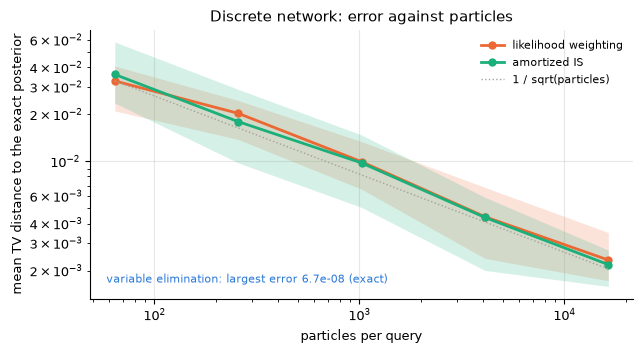

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for name, curve in (("likelihood weighting", lw_curve), ("amortized IS", ais_curve)):
    ax.plot(PARTICLES, curve.mean(1), "o-", color=ENGINE_COLORS[name], lw=2, ms=5, label=name)
    ax.fill_between(PARTICLES, curve.min(1), curve.max(1), color=ENGINE_COLORS[name], alpha=0.18, lw=0)
slope = lw_curve.mean(1)[0] * (np.array(PARTICLES) / PARTICLES[0]) ** -0.5
ax.plot(PARTICLES, slope, color=GREY, lw=1, ls=":", label="1 / sqrt(particles)")
ax.set(xscale="log", yscale="log", xlabel="particles per query",
       ylabel="mean TV distance to the exact posterior", title="Discrete network: error against particles")
ax.text(0.03, 0.06, f"variable elimination: largest error {ve_err:.1e} (exact)",
        transform=ax.transAxes, fontsize=8, color=ENGINE_COLORS["variable elimination"])
ax.legend(frameon=False, fontsize=8, loc="upper right")
fig.tight_layout()
plt.show()

VE is exact up to floating-point rounding.  The LW error falls like
`1 / sqrt(particles)` (dotted line): 0.033 at 64 particles, 0.0023 at 16384.
Amortized IS follows the same line on this small network.

The VI quality gate rejected its `q`: on held-out evidence, `q` was farther
from the LW reference (0.105) than the clamped prior was (0.052).  So `avi`
answers with LW.  Without the gate, the mean-field `q` (which treats the hidden
nodes as independent) has a mean TV of 0.163, about 16 times LW's error at
1024 particles.

`return_ess=True` makes LW (and AIS) also return the effective sample size
(ESS) of each query, as a fraction of the particles.  A low ESS means a few
particles carry most of the weight.

likelihood weighting   ESS fraction: [0.801, 0.499, 0.541, 0.652]
amortized IS           ESS fraction: [0.976, 0.982, 0.913, 0.991]


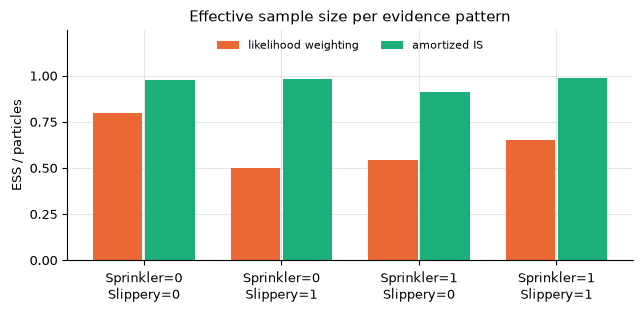

In [7]:
ess = {}
for name, engine in (("likelihood weighting", lw), ("amortized IS", ais)):
    seed_all(2)
    _, ess[name] = disc.query_batch(["Cloudy"], EVIDENCE, engine=engine, n_samples=4096,
                                    return_ess=True)
labels = [f"Sprinkler={int(a)}\nSlippery={int(b)}" for a, b in zip(EVIDENCE["Sprinkler"], EVIDENCE["Slippery"])]
for name, values in ess.items():
    print(f"{name:22s} ESS fraction:", [round(float(v), 3) for v in values])

fig, ax = plt.subplots(figsize=(6.5, 3.2))
x = np.arange(4)
for k, (name, values) in enumerate(ess.items()):
    ax.bar(x + (k - 0.5) * 0.38, to_numpy(values), 0.36, color=ENGINE_COLORS[name], label=name)
ax.set_xticks(x, labels)
ax.set(ylabel="ESS / particles", ylim=(0, 1.25), title="Effective sample size per evidence pattern")
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.legend(frameon=False, fontsize=8, loc="upper center", ncol=2)
fig.tight_layout()
plt.show()

The learned proposal raises the ESS from 0.50–0.80 (LW) to 0.91–0.99: almost
every particle counts.  Here LW's ESS is already at least 0.5, so the error
barely changes (previous plot).

## 4. `HybridRouter`: the default engine

A model's default engine is a `HybridRouter`.  It uses exact VE when every
node is discrete and the elimination fits in memory, and LW otherwise.
`last_engine` says which one answered.  We build the hybrid network now, fit
it from 5000 rows, and ask the router a question on each network.

In [8]:
H_EDGES = [("Rain", "Sprinkler"), ("Rain", "WetGrass"), ("Sprinkler", "WetGrass"), ("WetGrass", "Soil")]
H_VARS = {"Rain": ("discrete", 2), "Sprinkler": ("discrete", 2), "WetGrass": ("discrete", 2),
          "Soil": ("continuous", 1)}
H_RAIN = torch.tensor([0.7, 0.3])
H_SPRINKLER = torch.tensor([[0.5, 0.5], [0.9, 0.1]])
H_WET = torch.tensor([[[0.95, 0.05], [0.20, 0.80]], [[0.15, 0.85], [0.02, 0.98]]])


def normal_pdf(x, mean, std):
    return torch.exp(-0.5 * ((x - mean) / std) ** 2) / (std * math.sqrt(2 * math.pi))


def normal_cdf(x, mean, std):
    return torch.special.ndtr((x - mean) / std)


def soil_pdf(x, wet: int):
    if wet:
        return 0.5 * normal_pdf(x, 1.5, 0.3) + 0.5 * normal_pdf(x, 3.0, 0.3)
    return normal_pdf(x, -1.0, 0.5)


def soil_cdf(x, wet: int):
    if wet:
        return 0.5 * normal_cdf(x, 1.5, 0.3) + 0.5 * normal_cdf(x, 3.0, 0.3)
    return normal_cdf(x, -1.0, 0.5)


def h_sample(n: int) -> dict:
    rain = torch.multinomial(H_RAIN, n, replacement=True)
    sprinkler = torch.bernoulli(H_SPRINKLER[rain, 1]).long()
    wet = torch.bernoulli(H_WET[rain, sprinkler, 1]).long()
    soil_wet = torch.where(torch.rand(n) < 0.5, 3.0, 1.5) + 0.3 * torch.randn(n)
    soil = torch.where(wet == 1, soil_wet, -1.0 + 0.5 * torch.randn(n))
    return {"Rain": rain, "Sprinkler": sprinkler, "WetGrass": wet, "Soil": soil[:, None]}


seed_all(0)
hybrid = NeuralBayesianNetwork(H_EDGES, H_VARS, device=device)
hybrid.set_mechanism("Soil", MDNMechanism(num_components=3))
hybrid.auto_mechanisms()
hybrid.fit(h_sample(5000), consolidate=False)

router = HybridRouter()
disc.query(["Rain"], {"Slippery": 1}, engine=router)
print("discrete network ->", router.last_engine)
hybrid.query(["Rain"], {"Soil": 2.0}, engine=router)
print("hybrid network   ->", router.last_engine)

discrete network -> tensor_ve
hybrid network   -> likelihood_weighting


## 5. Evidence on a continuous node

`P(Rain = 1 | Soil = s)` for 61 values of `s` is one `query_batch` call: the
evidence is a `[61, 1]` tensor.  The exact curve sums over `Sprinkler` and
`WetGrass` with the true densities.  The model was learned from data, so the
gap to the truth contains both learning error and Monte-Carlo error.

P(Rain=1 | Soil=s) over 61 values of s: mean |error| 0.009, largest 0.041 at s = 0.62


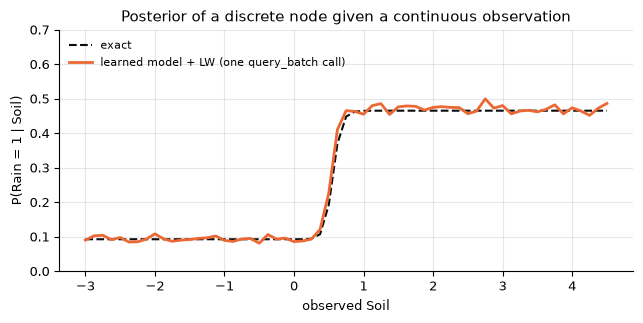

In [9]:
def exact_rain_given_soil(soil: torch.Tensor) -> torch.Tensor:
    """P(Rain = 1 | Soil = soil) under the true network."""
    post = []
    for rain in (0, 1):
        total = 0.0
        for spr, wet in itertools.product((0, 1), repeat=2):
            total = total + H_RAIN[rain] * H_SPRINKLER[rain, spr] * H_WET[rain, spr, wet] * soil_pdf(soil, wet)
        post.append(total)
    return post[1] / (post[0] + post[1])


soil_grid = torch.linspace(-3.0, 4.5, 61)
seed_all(3)
p_lw = hybrid.query_batch(["Rain"], {"Soil": soil_grid[:, None]}, n_samples=4096)
p_exact = exact_rain_given_soil(soil_grid)
err = (p_lw[:, 1].cpu() - p_exact).abs()
print(f"P(Rain=1 | Soil=s) over 61 values of s: mean |error| {float(err.mean()):.3f}, "
      f"largest {float(err.max()):.3f} at s = {float(soil_grid[err.argmax()]):.2f}")

fig, ax = plt.subplots(figsize=(6.5, 3.3))
ax.plot(to_numpy(soil_grid), to_numpy(p_exact), color=INK, lw=1.5, ls="--", label="exact")
ax.plot(to_numpy(soil_grid), to_numpy(p_lw[:, 1]), color=ORANGE, lw=2,
        label="learned model + LW (one query_batch call)")
ax.set(xlabel="observed Soil", ylabel="P(Rain = 1 | Soil)", ylim=(0, 0.7),
       title="Posterior of a discrete node given a continuous observation")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

The exact curve has two levels.  Soil below about 0.3 means the grass is dry,
and then `P(Rain = 1)` is about 0.09; soil above about 0.8 means the grass is
wet, and `P(Rain = 1)` is about 0.47.  The learned model with LW follows the
curve: the mean error is 0.009, and the largest (0.041) is on the steep step,
at `s = 0.62`.

## 6. A continuous target

For a continuous target, `query` returns weighted particles
`(weights [1, S], samples [1, S, 1])` instead of a probability vector.  We
compare them with the exact density of `Soil | Rain = 1, Sprinkler = 0`, and
measure the 1-Wasserstein distance `W1 = integral |F_particles(x) - F_true(x)| dx`.

weights (1, 8192)  samples (1, 8192, 1)
W1(particles, truth) = 0.040
     256 particles: W1 = 0.103 (mean of 5 runs)
    1024 particles: W1 = 0.065 (mean of 5 runs)
    4096 particles: W1 = 0.058 (mean of 5 runs)
   16384 particles: W1 = 0.043 (mean of 5 runs)
parents of WetGrass, in table-axis order: ['Rain', 'Sprinkler']
W1(learned model, truth) without any sampling = 0.044  (learning error only)


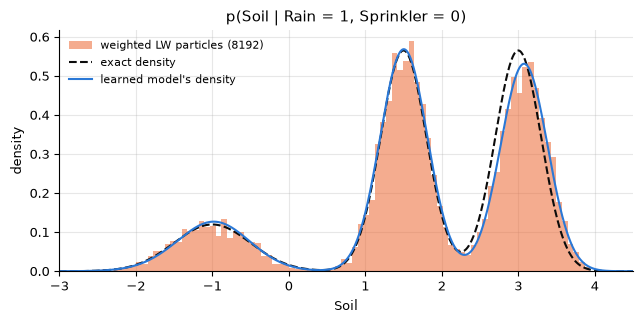

In [10]:
GRID = torch.linspace(-4.0, 6.0, 2001)


def w1_to_truth(weights, samples, true_cdf) -> float:
    x = samples.reshape(-1).cpu()
    wts = weights.reshape(-1).cpu()
    cdf = (wts[None, :] * (x[None, :] <= GRID[:, None])).sum(1)
    return float(torch.trapezoid((cdf - true_cdf(GRID)).abs(), GRID))


p_wet = H_WET[1, 0]                                # P(WetGrass | Rain=1, Sprinkler=0)
true_cdf = lambda x: p_wet[0] * soil_cdf(x, 0) + p_wet[1] * soil_cdf(x, 1)  # noqa: E731
true_pdf = p_wet[0] * soil_pdf(GRID, 0) + p_wet[1] * soil_pdf(GRID, 1)
seed_all(4)
weights, samples = hybrid.query(["Soil"], {"Rain": 1, "Sprinkler": 0}, n_samples=8192)
print("weights", tuple(weights.shape), " samples", tuple(samples.shape))
print(f"W1(particles, truth) = {w1_to_truth(weights, samples, true_cdf):.3f}")
for n in (256, 1024, 4096, 16384):
    seed_all(5)
    w1s = [w1_to_truth(*hybrid.query(["Soil"], {"Rain": 1, "Sprinkler": 0}, n_samples=n), true_cdf)
           for _ in range(5)]
    print(f"  {n:6d} particles: W1 = {np.mean(w1s):.3f} (mean of 5 runs)")

# The learned model's own exact answer, without sampling: learned P(WetGrass | Rain=1, Sprinkler=0)
# (parents in the order of hybrid.dag.parents) times the learned MDN density, integrated on GRID.
print("parents of WetGrass, in table-axis order:", hybrid.dag.parents("WetGrass"))
with torch.no_grad():
    lw_wet = hybrid.mechanisms["WetGrass"].tabulate([2, 2]).softmax(-1)[1, 0].cpu()
    mdn = hybrid.mechanisms["Soil"]
    learned_pdf = sum(lw_wet[k] * mdn.log_prob(GRID[:, None].to(device),
                                                torch.full((len(GRID), 1), float(k), device=device)).exp().cpu()
                      for k in (0, 1))
learned_cdf = torch.cumulative_trapezoid(learned_pdf, GRID)
learned_cdf = torch.cat([torch.zeros(1), learned_cdf])
w1_learning = float(torch.trapezoid((learned_cdf - true_cdf(GRID)).abs(), GRID))
print(f"W1(learned model, truth) without any sampling = {w1_learning:.3f}  (learning error only)")

fig, ax = plt.subplots(figsize=(6.5, 3.3))
ax.hist(to_numpy(samples).ravel(), bins=90, weights=to_numpy(weights).ravel(), density=True,
        color=ORANGE, alpha=0.55, label="weighted LW particles (8192)")
ax.plot(to_numpy(GRID), to_numpy(true_pdf), color=INK, lw=1.5, ls="--", label="exact density")
ax.plot(to_numpy(GRID), to_numpy(learned_pdf), color=BLUE, lw=1.5, label="learned model's density")
ax.set(xlim=(-3, 4.5), xlabel="Soil", ylabel="density", title="p(Soil | Rain = 1, Sprinkler = 0)")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

W1 falls from 0.103 with 256 particles to 0.043 with 16384.  The learned model
itself is 0.044 away from the truth (computed without any sampling), so with
many particles the error left is learning error, not inference error.  The
plot shows where it is: the learned upper mode (blue) sits slightly to the
right of the true one.

## 7. MAP queries and joint queries

`map_query(targets, evidence)` returns the most probable state of a single
discrete target.  On the discrete network it matches the exact argmax:

In [11]:
for spr, slip in itertools.product((0, 1), repeat=2):
    ev = {"Sprinkler": spr, "Slippery": slip}
    nbn_map = int(disc.map_query(["Rain"], ev)["Rain"])
    print(f"Sprinkler={spr}, Slippery={slip}:  MAP Rain = {nbn_map}   exact argmax = "
          f"{int(exact(['Rain'], ev).argmax())}   (P(Rain=1) = {float(exact(['Rain'], ev)[1]):.3f})")

Sprinkler=0, Slippery=0:  MAP Rain = 0   exact argmax = 0   (P(Rain=1) = 0.354)
Sprinkler=0, Slippery=1:  MAP Rain = 1   exact argmax = 1   (P(Rain=1) = 0.941)
Sprinkler=1, Slippery=0:  MAP Rain = 0   exact argmax = 0   (P(Rain=1) = 0.265)
Sprinkler=1, Slippery=1:  MAP Rain = 0   exact argmax = 0   (P(Rain=1) = 0.319)


With several discrete targets, VE returns the exact *joint* posterior, one axis
per target in the order given.  On the hybrid network the router uses LW and
returns joint particles: one column per target.

In [12]:
joint = disc.query(["Rain", "Sprinkler"], {"WetGrass": 1})
print("P(Rain, Sprinkler | WetGrass = 1), rows = Rain, columns = Sprinkler")
print("  NBN  :", [[round(float(v), 4) for v in row] for row in joint])
print("  exact:", [[round(float(v), 4) for v in row] for row in exact(["Rain", "Sprinkler"], {"WetGrass": 1})])

seed_all(6)
weights, samples = hybrid.query(["Rain", "Soil"], {"Sprinkler": 1}, n_samples=8192)
print("hybrid joint query: weights", tuple(weights.shape), " samples", tuple(samples.shape),
      "(columns: Rain, Soil)")
rain_col, soil_col = samples[0, :, 0], samples[0, :, 1]
p_est = float((weights[0] * ((rain_col == 1) & (soil_col > 2.25)).float()).sum())
# exact: P(Rain=1, Soil > 2.25 | Sprinkler=1)
num = 0.0
den = 0.0
for rain, wet in itertools.product((0, 1), repeat=2):
    pr = H_RAIN[rain] * H_SPRINKLER[rain, 1] * H_WET[rain, 1, wet]
    den += pr
    if rain == 1:
        num += pr * (1 - soil_cdf(torch.tensor(2.25), wet))
print(f"P(Rain = 1, Soil > 2.25 | Sprinkler = 1): NBN {p_est:.3f}, exact {float(num / den):.3f}")

P(Rain, Sprinkler | WetGrass = 1), rows = Rain, columns = Sprinkler
  NBN  : [[0.0045, 0.2908], [0.5677, 0.1371]]
  exact: [[0.0045, 0.2908], [0.5677, 0.1371]]
hybrid joint query: weights (1, 8192)  samples (1, 8192, 2) (columns: Rain, Soil)
P(Rain = 1, Soil > 2.25 | Sprinkler = 1): NBN 0.035, exact 0.039
